# *mathematical fun transformers : Log Transformer/ reciprocal/sqare root *

In [1]:
import pandas as pd
import numpy as np


import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score


from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [2]:
df = pd.read_csv('train.csv' , usecols= ['Age', 'Fare', 'Survived'])

In [3]:
df['Age'].fillna(df['Age'].mean() , inplace =True)

/tmp/ipykernel_1843/857096105.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean() , inplace =True)


In [4]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [5]:
# Separating features (X) and target (y) variables.
# X contains 'Age' and 'Fare' columns (features for prediction).
X = df.iloc[:,1:3]
# y contains the 'Survived' column (the target variable).
y= df.iloc[:,0]

In [6]:
X_train , X_test ,y_train , y_test = train_test_split(X,y,test_size =0.2, random_state =42)

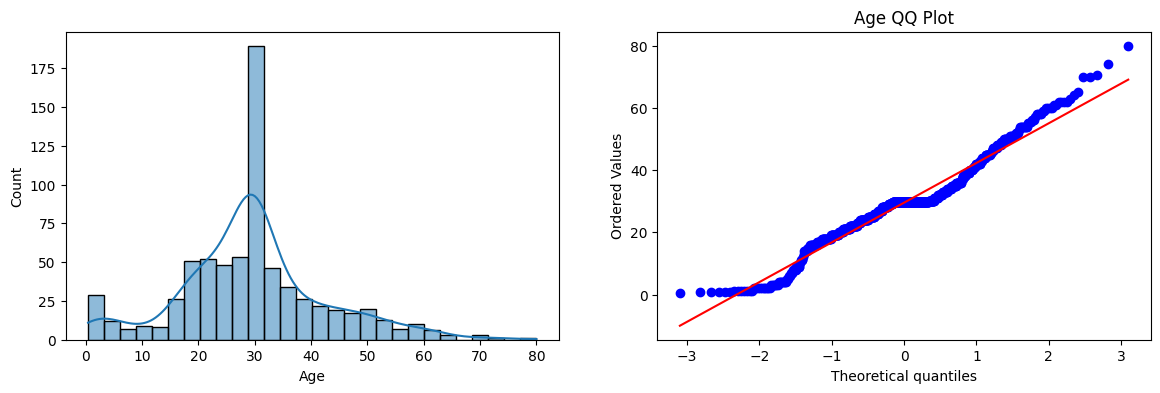

In [7]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.histplot(X_train['Age'], kde=True) # Changed from distlot to histplot
plt.subplot(122)
stats.probplot(X_train['Age'], dist='norm', plot=plt)
plt.title('Age QQ Plot')
plt.show()

In [8]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [9]:
clf.fit(X_train, y_train)
clf2.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_pred2 = clf2.predict(X_test)

print("Accuracy LR", accuracy_score(y_test, y_pred))
print("Accuracy DT", accuracy_score(y_test, y_pred2))

Accuracy LR 0.6480446927374302
Accuracy DT 0.6703910614525139


In [10]:
trf = FunctionTransformer(func = np.log1p)

In [11]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [12]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_trf, y_train)
clf2.fit(X_train_trf, y_train)

y_pred = clf.predict(X_test_trf)
y_pred2 = clf2.predict(X_test_trf)

print("Accuracy LR", accuracy_score(y_test, y_pred))
print("Accuracy DT", accuracy_score(y_test, y_pred2))

Accuracy LR 0.6815642458100558
Accuracy DT 0.6759776536312849


In [13]:
#crossvald

X_transformed = trf.fit_transform(X)


clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR", cross_val_score(clf, X_transformed, y, cv=5, scoring='accuracy').mean())
print("DT", cross_val_score(clf2, X_transformed, y, cv=5, scoring='accuracy').mean() )

LR 0.6780114242671521
DT 0.6453455526960015


Text(0.5, 1.0, 'Fare After log')

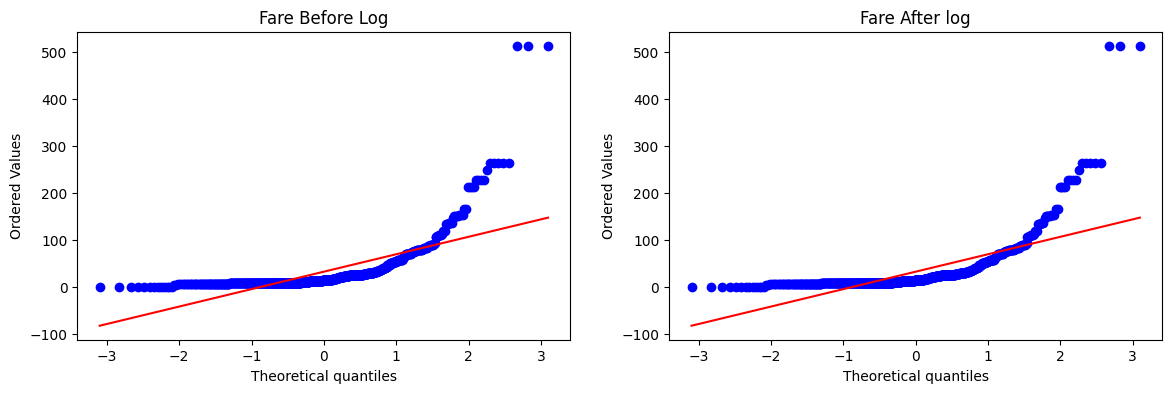

In [14]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Fare'], dist = "norm" , plot =plt)
plt.title('Fare Before Log')


plt.subplot(122)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('Fare After log')

In [15]:
trf2 = ColumnTransformer([('log', FunctionTransformer(np.log1p), ['Fare'])], remainder='passthrough')

X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.transform(X_test)

In [16]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed2, y_train)
clf2.fit(X_train_transformed2, y_train)

y_pred = clf.predict(X_test_transformed2)
y_pred2 = clf2.predict(X_test_transformed2)

print("Accuracy LR", accuracy_score(y_test, y_pred))
print("Accuracy DT", accuracy_score(y_test, y_pred2))

Accuracy LR 0.6703910614525139
Accuracy DT 0.659217877094972


Accuracy 0.6712609238451936


Text(0.5, 1.0, 'Fare After log')

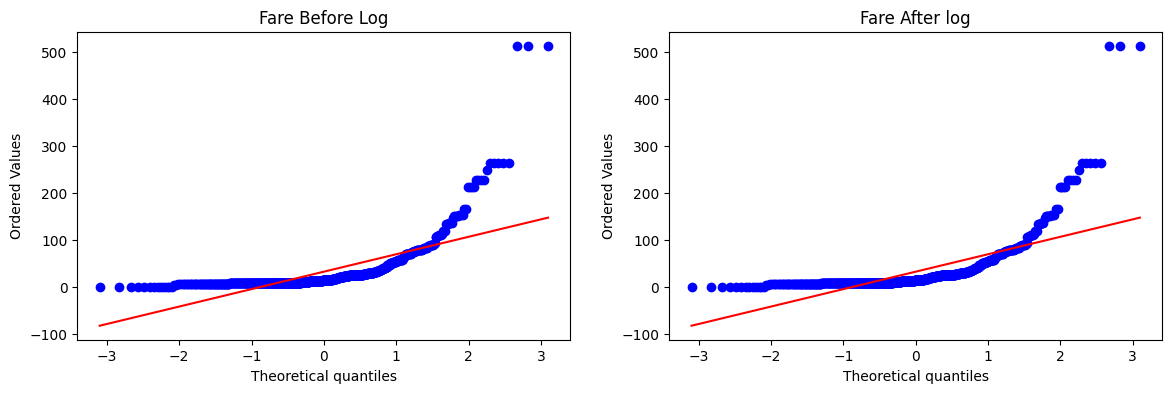

In [17]:
X= df.iloc[:,1:3]
y= df.iloc[:,0]

trf = ColumnTransformer([('log', FunctionTransformer(np.log1p), ['Fare'])], remainder='passthrough')

X_transformed = trf.fit_transform(X)

clf = LogisticRegression()

print("Accuracy" , np.mean(cross_val_score(clf, X_transformed, y, scoring= 'accuracy', cv=10)))

plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Fare'], dist = "norm" , plot =plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('Fare After log')

In [18]:
def apply_transform(transform_func):
    # This is a placeholder function.
    # You need to define what this function should do.
    # For example, it might apply the 'transform_func' to your dataframes.
    print(f"Applying transform: {transform_func}")
    # Example: return transform_func(df)
    pass

In [19]:
apply_transform(lambda x: x)
apply_transform(lambda x: x * 2)
apply_transform(lambda x: x + 10)

Applying transform: <function <lambda> at 0x7d3143770400>
Applying transform: <function <lambda> at 0x7d3143770400>
Applying transform: <function <lambda> at 0x7d3143770400>


# **Power Transformer**: Box-Cox transform and Yeo-Johnson

In [20]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns



In [21]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import accuracy_score

In [22]:
df   = pd.read_csv('concrete_data.csv')

In [23]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [24]:
df.shape

(1030, 9)

In [25]:
df.isnull().sum()

,0
Cement,0
Blast Furnace Slag,0
Fly Ash,0
Water,0
Superplasticizer,0
Coarse Aggregate,0
Fine Aggregate,0
Age,0
Strength,0


In [26]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [27]:
X = df.drop(columns=['Strength'])
y = df.iloc[:,-1]

In [28]:
X_train , X_test, y_train, y_test = train_test_split(X,y,test_size =0.2, random_state =42)

In [29]:
#applying regression without any transformation

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

r2_score(y_test, y_pred)

0.627553179231485

In [30]:
#cross checking with cross val score

lr =  LinearRegression()
np.mean(cross_val_score(lr,X,y,scoring='r2'))

np.float64(0.46099404916628606)

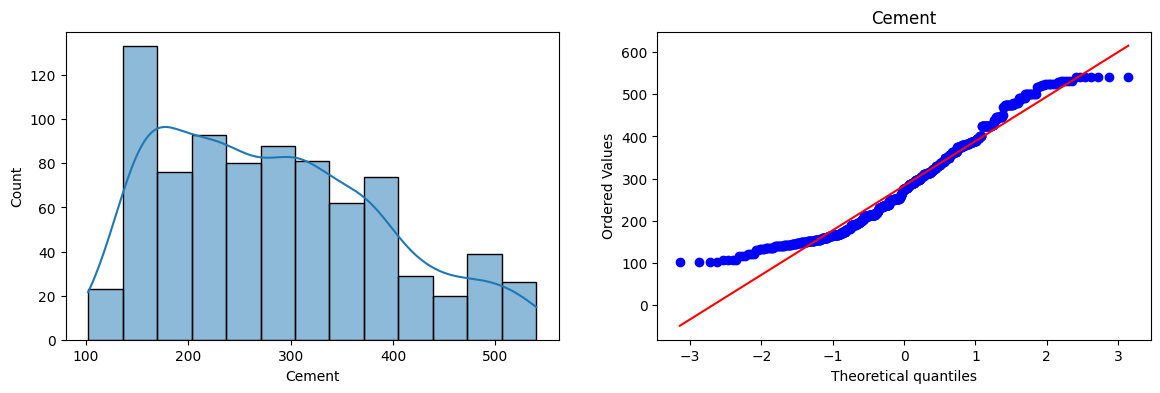

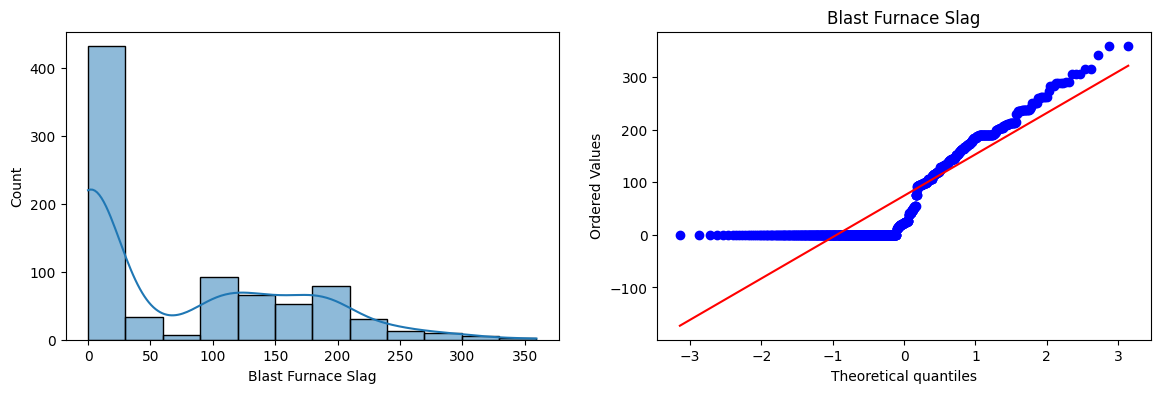

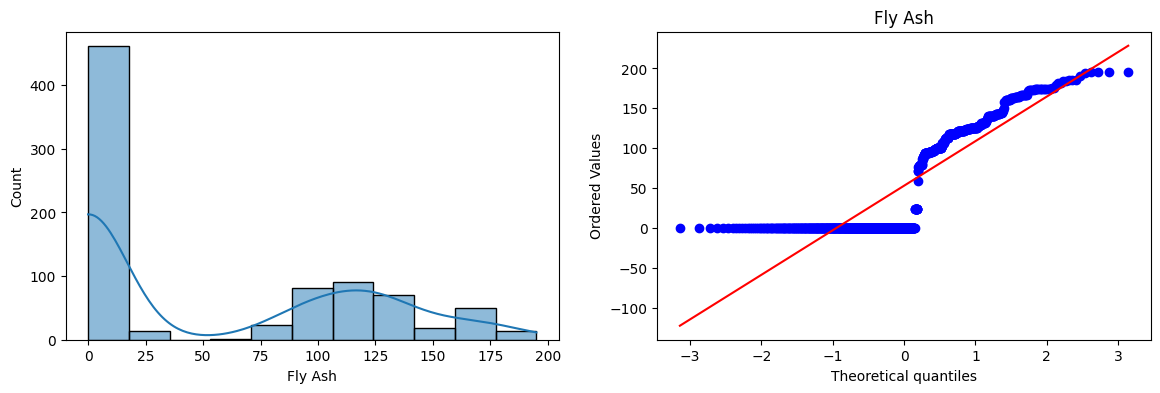

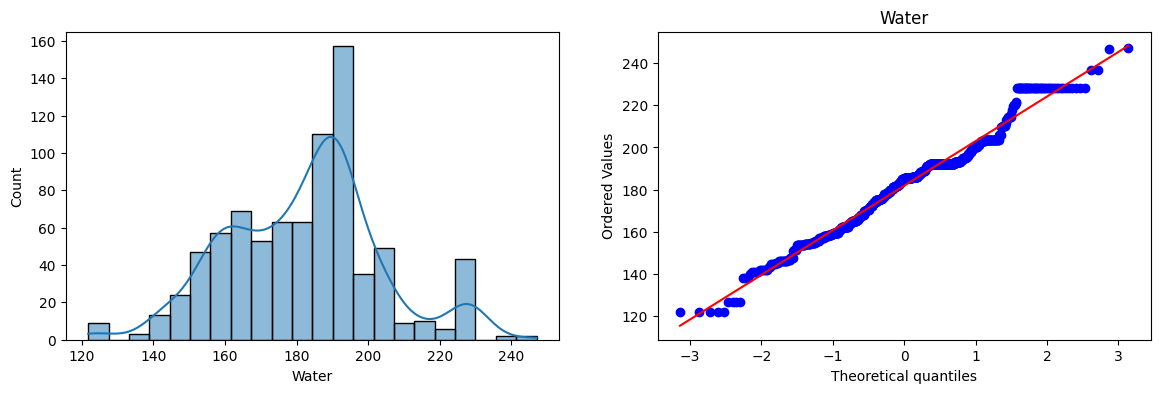

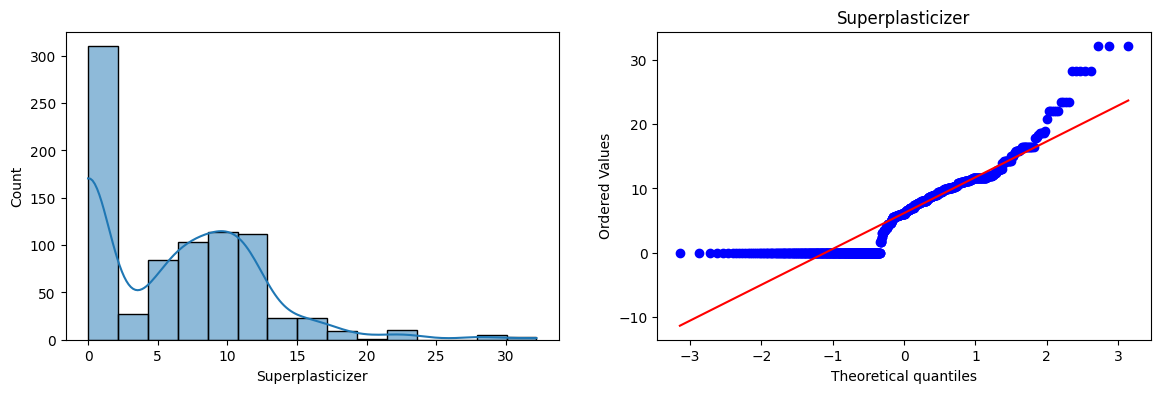

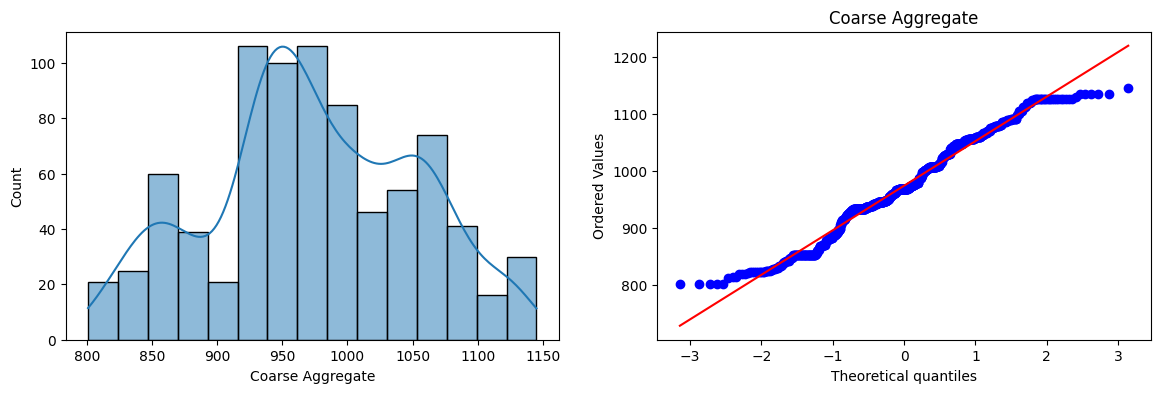

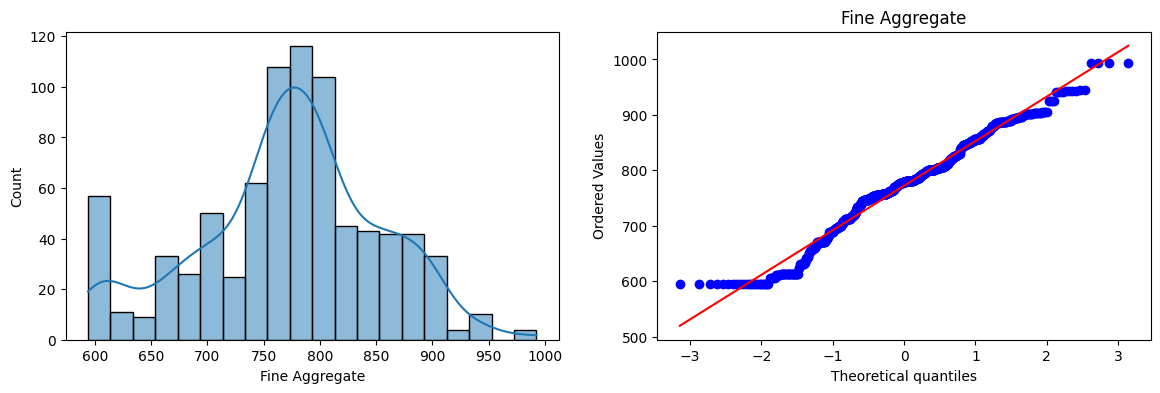

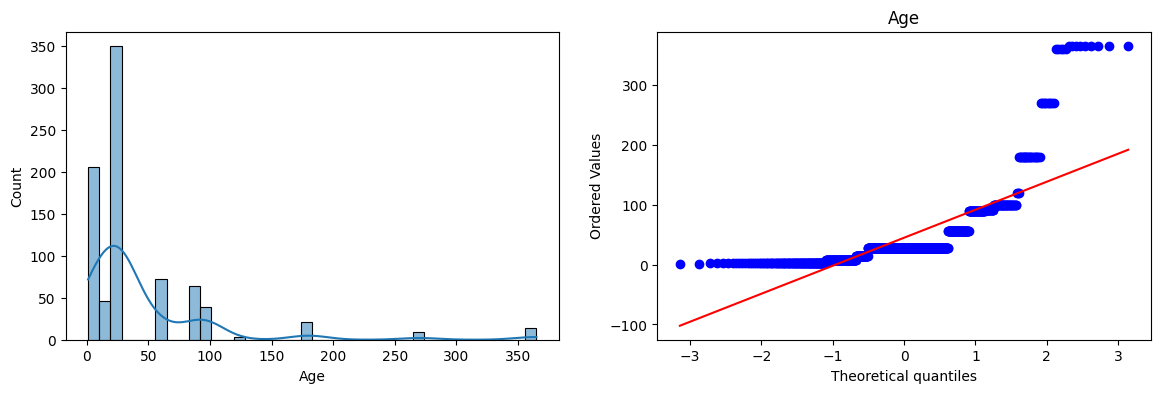

In [31]:
#plotting the distplots qithout any trnsformations

for col in X_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col], kde=True)

    plt.subplot(122)

    stats.probplot(X_train[col], dist='norm', plot=plt)
    plt.title(col)

    plt.show()

In [39]:
#applying Box-Cox Transform

power_transformer = PowerTransformer(method='box-cox')

X_train_transformesd = power_transformer.fit_transform(X_train+0.000001)
X_test_transformed = power_transformer.transform(X_test+0.000001)

pd.DataFrame({'cols': X_train.columns, 'box_cox_lambdas': power_transformer.lambdas_})

,cols,box_cox_lambdas
0,Cement,0.177025
1,Blast Furnace Slag,0.025093
2,Fly Ash,-0.038970
3,Water,0.772682
4,Superplasticizer,0.098811
5,Coarse Aggregate,1.129813
6,Fine Aggregate,1.782018
7,Age,0.066631


In [35]:
#applying  linear regression on transfromed data

lr = LinearRegression()
lr.fit(X_train_transformesd, y_train)

y_pred = lr.predict(X_test_transformed)

r2_score(y_test, y_pred)

0.8047824993092503

In [36]:
#using cross val score

pt = PowerTransformer(method='box-cox')
X_transformed = pt.fit_transform(X+0.000001)

lr = LinearRegression()
np.mean(cross_val_score(lr,X_transformed,y,scoring='r2'))


np.float64(0.6662950329054064)

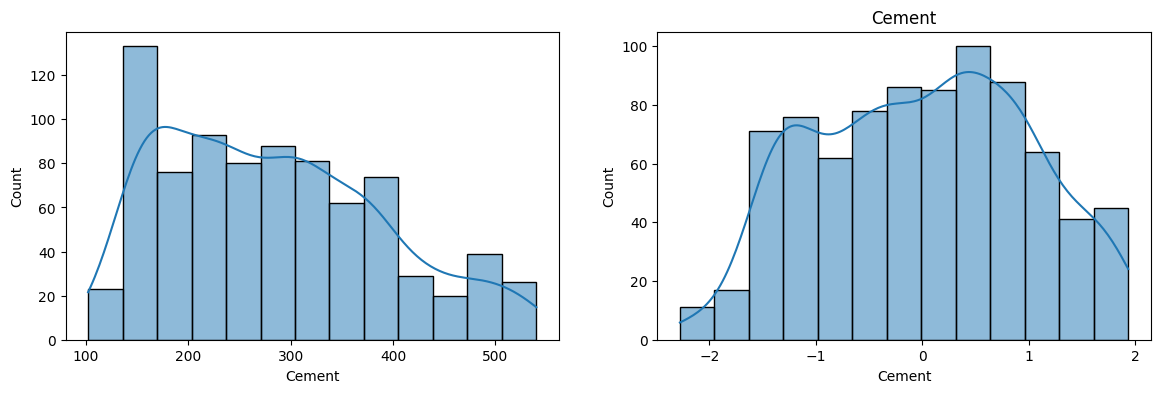

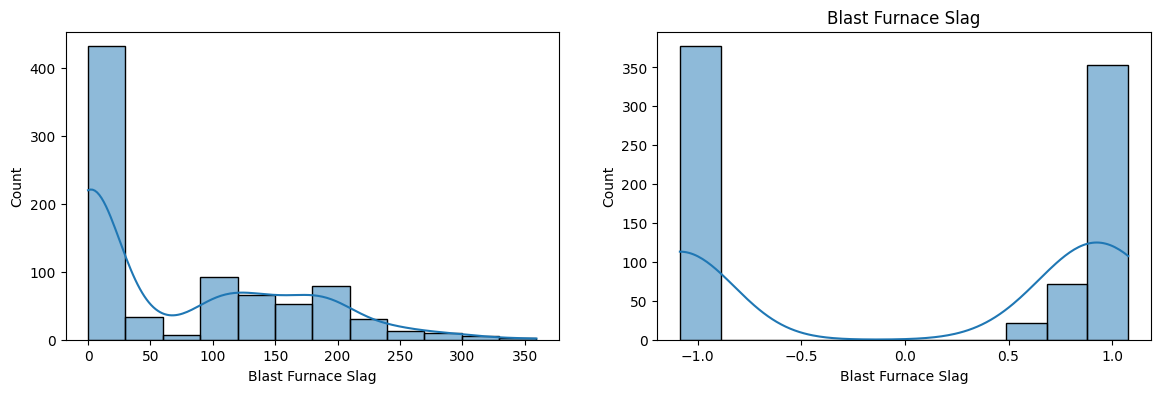

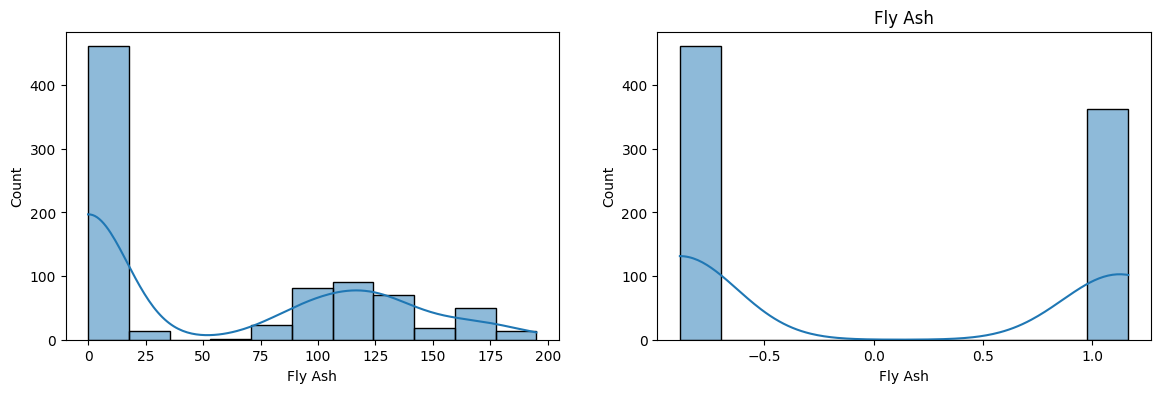

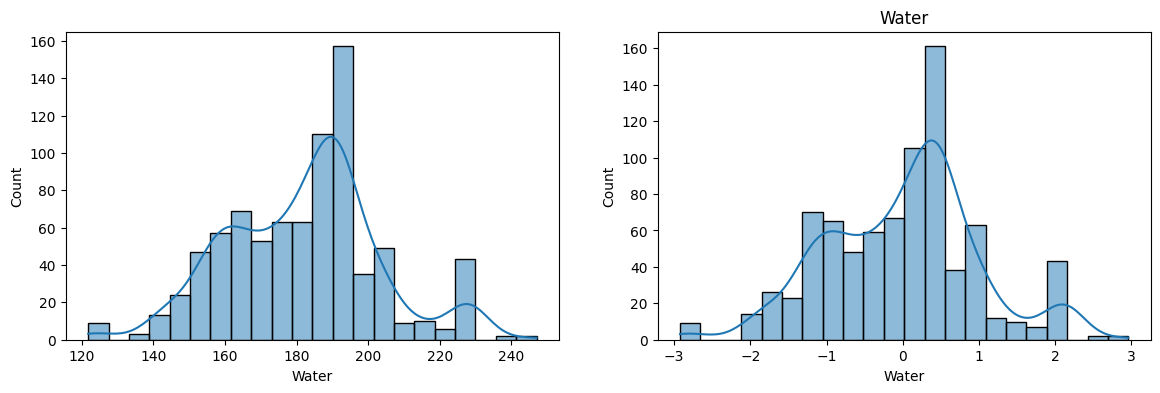

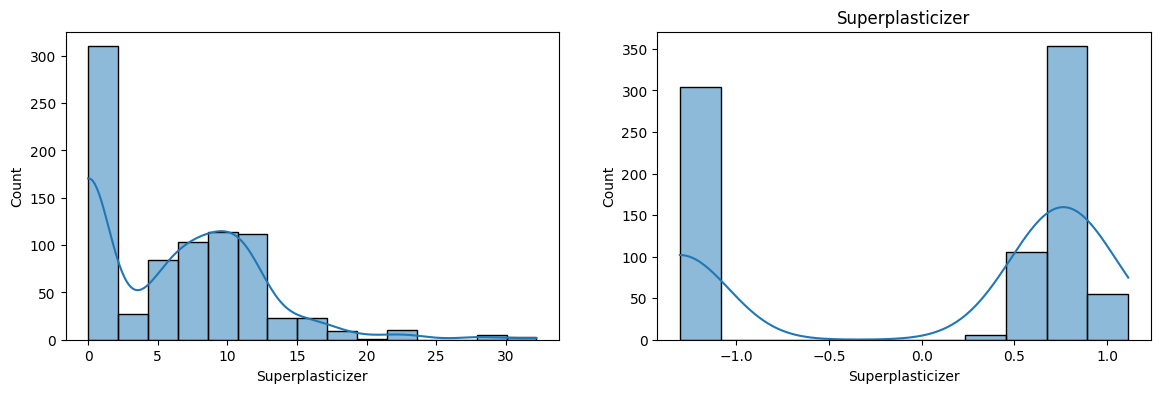

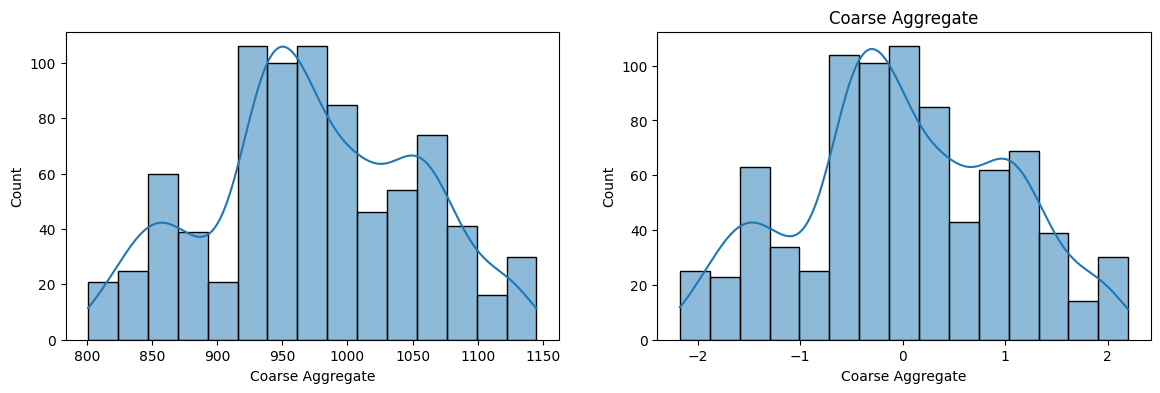

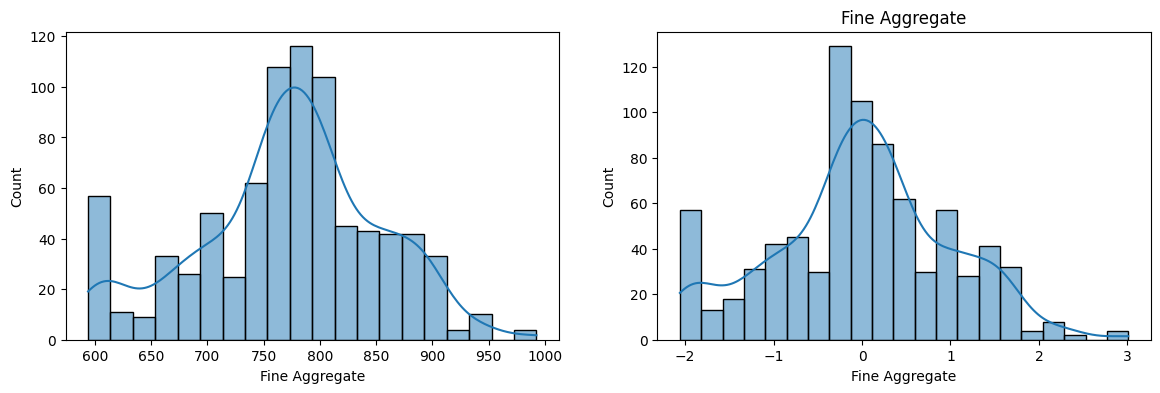

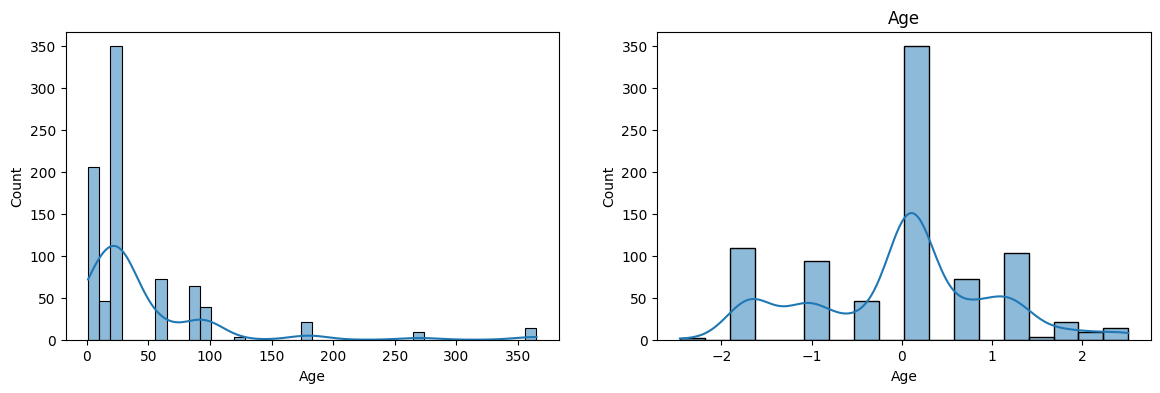

In [42]:

#beforeand after comparision for box- cox plot
import matplotlib.pyplot as plt
X_train_transformesd_df = pd.DataFrame(X_train_transformesd, columns=X_train.columns)

for col in X_train_transformesd_df.columns:
   plt.figure(figsize=(14,4))
   plt.subplot(121)
   sns.histplot(X_train[col], kde=True)

   plt.subplot(122)
   sns.histplot(X_train_transformesd_df[col], kde=True)
   plt.title(col)

   plt.show()

In [45]:
#apply Yeo-Johnson transform

pt1 = PowerTransformer()

X_train_transformed2 = pt1.fit_transform(X_train+0.000001)
X_test_transformed2 = pt1.transform(X_test+0.000001)

lr = LinearRegression()
lr.fit(X_train_transformed2, y_train)

y_pred = lr.predict(X_test_transformed2)

r2_score(y_test, y_pred)
pd.DataFrame({'cols': X_train.columns, 'Yeo_Johnson_lambdas': pt1.lambdas_})

,cols,Yeo_Johnson_lambdas
0,Cement,0.174348
1,Blast Furnace Slag,0.015715
2,Fly Ash,-0.161447
3,Water,0.771307
4,Superplasticizer,0.253935
5,Coarse Aggregate,1.130050
6,Fine Aggregate,1.783100
7,Age,0.019885


In [46]:
# applying cross val score

pt = PowerTransformer()
X_transformed = pt.fit_transform(X+0.000001)

lr = LinearRegression()
np.mean(cross_val_score(lr,X_transformed,y,scoring='r2'))


np.float64(0.6834625228904349)

In [47]:
X_train_transformed2 = pd.DataFrame(X_train_transformed2, columns=X_train.columns)

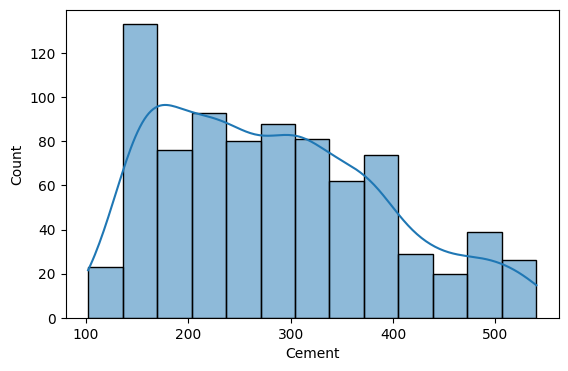

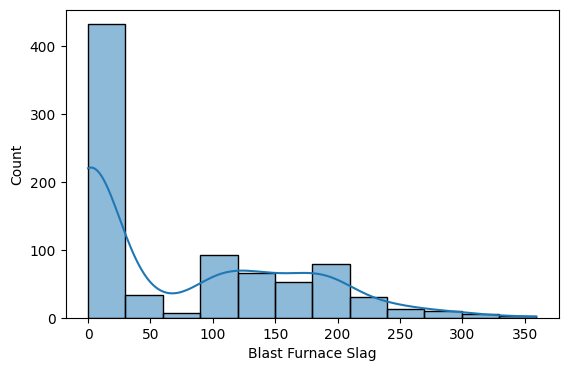

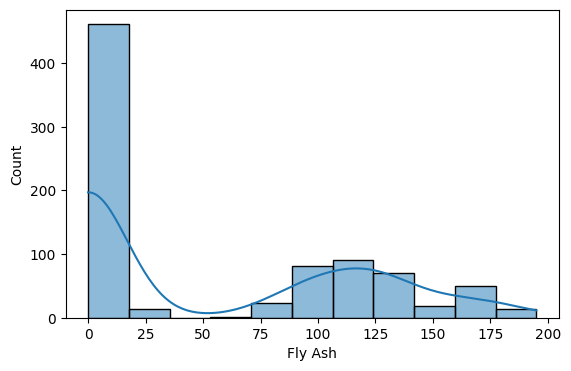

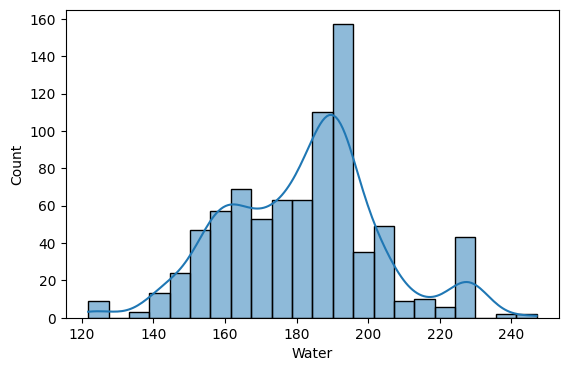

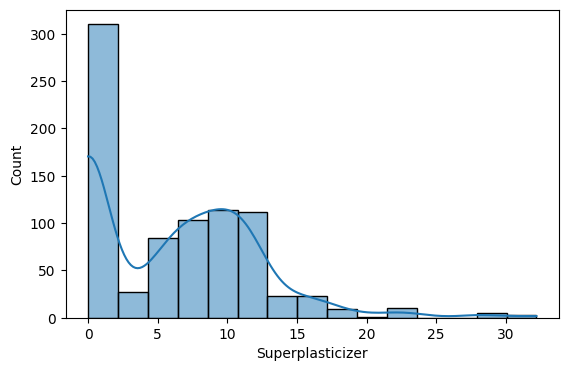

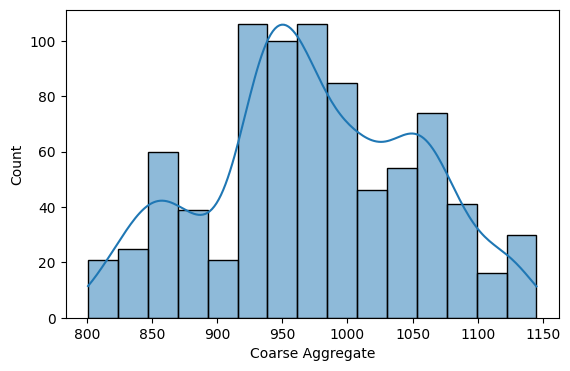

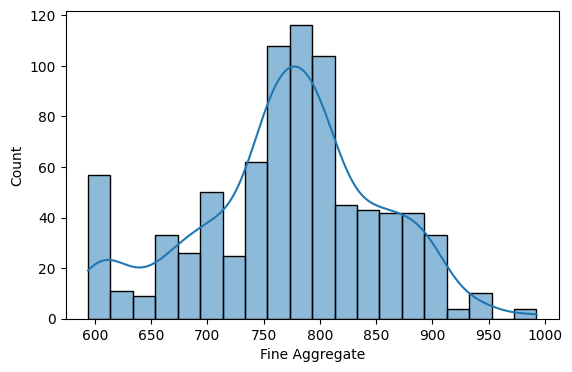

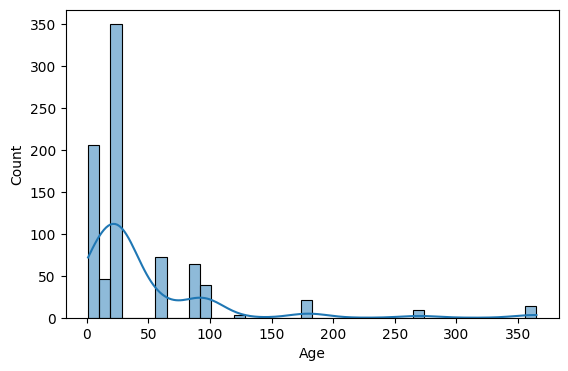

In [48]:
#Before and after comparision

for col in X_train_transformed2.columns:
   plt.figure(figsize=(14,4))
   plt.subplot(121)
   sns.histplot(X_train[col], kde=True)



In [49]:
#side by side lambdas

pd.DataFrame({'cols': X_train.columns, 'box_cox_lambdas': power_transformer.lambdas_, 'Yeo_Johnson_lambdas': pt1.lambdas_})

,cols,box_cox_lambdas,Yeo_Johnson_lambdas
0,Cement,0.177025,0.174348
1,Blast Furnace Slag,0.025093,0.015715
2,Fly Ash,-0.038970,-0.161447
3,Water,0.772682,0.771307
4,Superplasticizer,0.098811,0.253935
5,Coarse Aggregate,1.129813,1.130050
6,Fine Aggregate,1.782018,1.783100
7,Age,0.066631,0.019885
